# Automobile: linear vs quadratic regression (small regression dataset)

**Data:** UCI *Automobile* (imports-85), 205 cars, 25 features (sizes, engine, make, ...).
**Target:** `price`. **Metric:** mean squared error (MSE).

Steps of the lab covered here:
1. learning curves for **linear regression** (train and validation MSE vs. training-set size)
2. the same for **quadratic regression**
3. **cross-validation** to choose between the two, compared with 1. and 2.

The code lives in `lab/`: the loader `lab/data_automobile.py`, the models `lab/models.py`,
the experiment loop `lab/experiment.py` and the plots `lab/plotting.py`.

In [1]:
import sys
sys.path.append("..")  # make the lab/ package (one folder up) importable

import pandas as pd
from IPython.display import display

from lab import FIGURES_DIR, RESULTS_DIR
from lab.experiment import baseline_score, cross_validate_models, run_learning_curve, summarize
from lab.models import make_model
from lab.plotting import plot_learning_curve

# TODO: replace with Jakob's modules once they exist:
#   from lab.split import train_val_split
#   from lab.sampler import sample_training_sets, linear_sizes, log_sizes
from lab.temp_prep import linear_sizes, log_sizes, sample_training_sets, train_val_split

RESULTS_DIR.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:.4g}".format)

In [2]:
DATASET = "automobile"
TASK = "regression"
KINDS = ["linear", "quadratic"]
N_REPEATS = 10   # how many different random samples per training-set size

## Load the data
The loader reads `?` as missing, drops the 4 cars without a price and turns the word
columns `num-of-doors` / `num-of-cylinders` into numbers. Remaining missing values are
filled in by the model pipeline (median / most frequent value of the *training sample*).

In [3]:
from lab.data_automobile import load_automobile

X, y = load_automobile()
print(X.shape)
display(X.head())
print("missing values per column:")
print(X.isna().sum()[X.isna().sum() > 0])

(201, 25)


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg
0,3,NaN,alfa-romero,gas,std,2,convertible,rwd,front,88.6,...,4,130,mpfi,3.47,2.68,9,111,5000,21,27
1,3,NaN,alfa-romero,gas,std,2,convertible,rwd,front,88.6,...,4,130,mpfi,3.47,2.68,9,111,5000,21,27
2,1,NaN,alfa-romero,gas,std,2,hatchback,rwd,front,94.5,...,6,152,mpfi,2.68,3.47,9,154,5000,19,26
3,2,164,audi,gas,std,4,sedan,fwd,front,99.8,...,4,109,mpfi,3.19,3.4,10,102,5500,24,30
4,2,164,audi,gas,std,4,sedan,4wd,front,99.4,...,5,136,mpfi,3.19,3.4,8,115,5500,18,22


missing values per column:
normalized-losses    37
num-of-doors          2
bore                  4
stroke                4
horsepower            2
peak-rpm              2
dtype: int64


## Train / validation split
20% of the cars are set aside as the validation set. They are never used for fitting,
only for measuring the error.

In [4]:
X_train, X_val, y_train, y_val = train_val_split(X, y, TASK)
print(f"training part: {len(X_train)} rows, validation: {len(X_val)} rows")

training part: 160 rows, validation: 41 rows


In [5]:
# How many features does each model actually see? (after one-hot / squaring)
# Compare these numbers with the training-set sizes on the x-axis below.
for kind in KINDS:
    prep = make_model(kind).named_steps["prep"].fit(X_train)
    print(f"{kind:>20}: {prep.transform(X_train.iloc[:5]).shape[1]} features")

              linear: 67 features
           quadratic: 220 features


Note that the number of features `p` is **larger than** most (linear) or all (quadratic)
of our training-set sizes `n`. This explains a lot of the curves below. Only numeric
columns are squared for the quadratic model; see the docstring of `lab/models.py` for why.

## Steps 1 & 2: learning curves

In [6]:
# Training-set sizes 10, 20, ..., up to the whole training part.
sizes = linear_sizes(10, len(X_train), 10)
if sizes[-1] != len(X_train):
    sizes.append(len(X_train))
print(sizes)

samples = sample_training_sets(y_train, sizes, N_REPEATS, TASK)
curve = run_learning_curve(X_train, y_train, X_val, y_val, KINDS, samples, TASK, verbose=False)
curve.to_csv(RESULTS_DIR / f"{DATASET}_curve.csv", index=False)

stats = summarize(curve)
display(stats)

[10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150, 160]


model size train_score                                          \
                          mean       std    median       q25       q75   
0      linear   10   3.132e-23 2.806e-23 2.399e-23  1.76e-23 3.061e-23   
1      linear   20        7656 2.421e+04 1.572e-22 7.036e-23 1.099e-21   
2      linear   30        5326 1.684e+04 2.824e-22 1.511e-22 5.614e-22   
3      linear   40        1012      3202 4.808e-22 1.759e-22 8.738e-22   
4      linear   50   7.977e+04 8.449e+04 5.291e+04 1.471e+04 1.453e+05   
5      linear   60   2.632e+05 1.095e+05 2.598e+05 1.863e+05 3.321e+05   
6      linear   70   6.339e+05 2.788e+05  5.67e+05 4.771e+05 6.626e+05   
7      linear   80   6.716e+05 2.438e+05 6.699e+05  4.69e+05 8.209e+05   
8      linear   90   8.537e+05 3.082e+05 7.137e+05 6.211e+05 1.003e+06   
9      linear  100   1.001e+06 3.306e+05 9.256e+05 7.613e+05 1.156e+06   
10     linear  110   1.252e+06 3.289e+05 1.217e+06 1.027e+06  1.51e+06   
11     linear  120   1.469e+06 2.869e+05   1.6e+06   1.2e+06 1.682e+06   
12     linear  130   1.583e+06 1.919e+05 1.625e+06 1.465e+06 1.708e+06   
13     linear  140   1.496e+06 3.912e+05 1.531e+06 1.194e+06 1.844e+06   
14     linear  150    1.68e+06 2.457e+05 1.768e+06  1.66e+06 1.859e+06   
15     linear  160   1.821e+06         0 1.821e+06 1.821e+06 1.821e+06   
16  quadratic   10    3.94e-23 2.509e-23 3.582e-23 2.978e-23 4.595e-23   
17  quadratic   20        7656 2.421e+04 5.449e-23 3.617e-23 1.569e-22   
18  quadratic   30        1838      5811 1.483e-22  9.06e-23 3.972e-22   
19  quadratic   40        1012      3202 2.319e-22 1.011e-22 3.495e-22   
20  quadratic   50   1.997e+04  3.94e+04     2e-20 8.031e-22      8269   
21  quadratic   60   1.471e+04 2.811e+04 4.213e-21 1.178e-21 2.089e+04   
22  quadratic   70   2.928e+04 3.292e+04 2.187e+04      1446 5.384e+04   
23  quadratic   80   2.471e+04 3.667e+04      5159  5.77e-20 4.785e+04   
24  quadratic   90   2.606e+04 2.591e+04 1.305e+04      6125 5.367e+04   
25  quadratic  100   2.354e+04 2.425e+04 1.531e+04      5217 4.291e+04   
26  quadratic  110   3.226e+04  2.38e+04 4.289e+04      7801 5.264e+04   
27  quadratic  120   3.827e+04 1.986e+04 4.511e+04 1.991e+04 5.639e+04   
28  quadratic  130   3.588e+04 1.627e+04 4.215e+04 1.919e+04 4.974e+04   
29  quadratic  140   3.991e+04 2.043e+04   5.2e+04 2.647e+04 5.302e+04   
30  quadratic  150   4.515e+04 1.039e+04 4.979e+04 4.183e+04 5.021e+04   
31  quadratic  160   4.989e+04         0 4.989e+04 4.989e+04 4.989e+04   

   val_score                                          
        mean       std    median       q25       q75  
0   7.56e+07 7.122e+07   4.7e+07 4.208e+07 7.129e+07  
1  4.962e+08 1.412e+09 4.748e+07 3.423e+07 7.901e+07  
2  1.992e+08 2.394e+08 7.376e+07 5.396e+07 2.549e+08  
3  4.919e+08 6.181e+08 2.477e+08 6.978e+07 5.767e+08  
4  3.744e+11 1.183e+12 2.576e+08 1.623e+08 5.701e+08  
5   4.28e+07 2.929e+07 3.734e+07 1.882e+07 5.655e+07  
6  4.304e+07 3.953e+07 2.227e+07 1.874e+07 5.178e+07  
7  3.284e+07 2.342e+07 2.756e+07 1.671e+07 4.422e+07  
8  2.335e+07 1.103e+07 2.077e+07 1.602e+07 2.748e+07  
9  2.282e+07 1.626e+07 1.734e+07 1.446e+07 2.034e+07  
10 1.243e+07 4.753e+06 1.063e+07 9.859e+06 1.378e+07  
11 1.266e+07 6.703e+06 1.047e+07 8.626e+06 1.306e+07  
12 1.186e+07 5.066e+06  9.99e+06 7.834e+06 1.524e+07  
13 1.644e+07 1.013e+07 1.224e+07 1.085e+07 1.993e+07  
14 1.028e+07 6.413e+06 8.193e+06 7.502e+06 8.449e+06  
15 7.815e+06         0 7.815e+06 7.815e+06 7.815e+06  
16 2.773e+08 7.119e+08 4.481e+07 3.618e+07 5.167e+07  
17 4.877e+08 1.332e+09 6.753e+07 3.662e+07 9.544e+07  
18 5.796e+08 1.512e+09 6.214e+07 4.899e+07 1.443e+08  
19 1.417e+08 1.983e+08  5.64e+07 3.146e+07  1.22e+08  
20 8.943e+08 9.026e+08 4.787e+08 1.362e+08 1.857e+09  
21 6.784e+08 1.814e+09 8.143e+07 4.337e+07 1.536e+08  
22 7.062e+08 1.113e+09 1.801e+08 7.281e+07 8.827e+08  
23 1.056e+09 1.459e+09 3.542e+08   1.4e+08 9.237e+08  
24 2.463e+09 5.373e+09  8.81e+08 3.774e+08 1.337e+09  
25 3.6

baseline validation MSE: 1.32e+08  (RMSE $11,489)


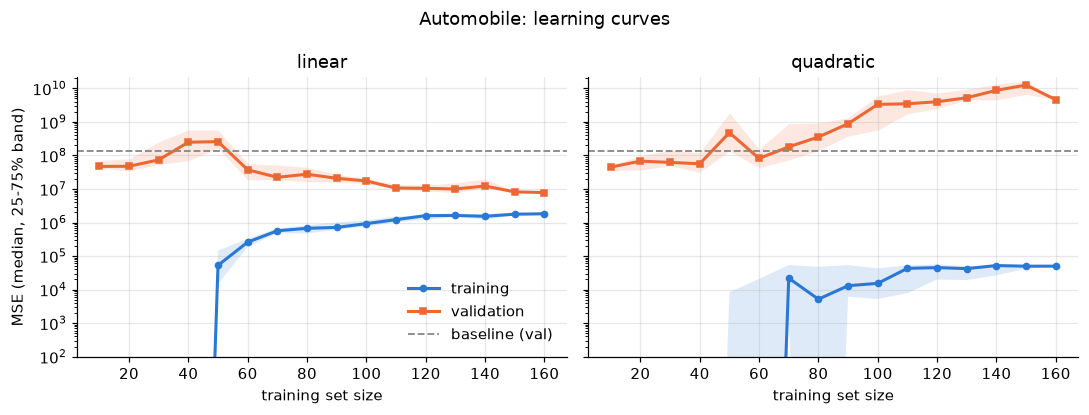

In [7]:
# Reference: always predict the mean price of the training part.
baseline = baseline_score(X_train, y_train, X_val, y_val, TASK)
print(f"baseline validation MSE: {baseline:.4g}  (RMSE ${baseline ** 0.5:,.0f})")

# Training MSE is exactly 0 for the smallest samples, which a log axis cannot show;
# ylim cuts the axis at 100 so those points simply drop off the bottom.
fig = plot_learning_curve(curve, "MSE", "Automobile: learning curves", baseline=baseline,
                          log_y=True, ylim=(1e2, None),
                          path=FIGURES_DIR / f"{DATASET}_learning_curves.png")

### What the curves show (step 1d)

**Training error (blue).** For small samples the training MSE is (numerically) **zero**:
when there are at least as many features as data points, least squares can pass the
fitted function exactly through every training point. Once `n` exceeds the number of
*effectively independent* features, this is no longer possible and the training MSE
rises, levelling off at the error the model cannot avoid (noise + what a linear function
cannot express). The effective number is smaller than the printed feature count:
one-hot columns of makes that are not in the sample are all zero, and some columns are
nearly copies of each other (e.g. `city-mpg` / `highway-mpg`).

**Validation error (orange).** With few points the model learns noise, so the
validation MSE is high, often worse than the baseline. It is **largest around
`n ≈ p`**: there the model is forced to fit every point exactly with a nearly singular
system, which needs huge coefficients that generalize badly (the peak of the so-called
*double descent* curve). With more data than features the validation MSE falls and
moves towards the training MSE. The gap between the two curves is the overfitting
(variance); where they would meet is the bias + noise level.

**Linear vs quadratic.** The quadratic model has more features than our whole
training part, so it never leaves the "too few data points" regime: its training MSE
stays tiny and its validation MSE gets *worse* as `n` approaches `p` (we only see the
left side of the double-descent peak). With ~160 cars there is simply not enough data to
estimate ~220 coefficients without regularization.

**Variability.** The shaded band (25-75% of the repeated samples) is wide for small `n`:
which cars end up in a sample matters a lot. At the largest size every repeat uses the
whole training part, so the band disappears.

## Step 3: cross-validation
5-fold CV on the training part only (the validation set stays untouched). Each fold
trains on 4/5 of the training part (~128 cars) and is scored on the remaining 1/5.

In [8]:
cv = cross_validate_models(X_train, y_train, KINDS, TASK, k=5)
cv.to_csv(RESULTS_DIR / f"{DATASET}_cv.csv", index=False)

# Put the CV estimate next to the learning-curve values at the largest size.
largest = stats[stats["size"] == stats["size"].max()]
curve_end = pd.DataFrame({
    "model": largest["model"],
    "curve_train": largest[("train_score", "median")],
    "curve_val": largest[("val_score", "median")],
})
comparison = cv.merge(curve_end, on="model")
display(comparison)
print("CV chooses:", cv.loc[cv["cv_mean"].idxmin(), "model"])

,model,cv_mean,cv_std,n_rows,curve_train,curve_val
0,linear,9.912e+06,2.854e+06,160,1.821e+06,7.815e+06
1,quadratic,1.986e+10,2.014e+10,160,4.989e+04,4.61e+09


CV chooses: linear


### CV vs. the learning curves (step 3)

CV clearly prefers the **linear** model, in agreement with the validation curves.

- The CV error is far above the **training** error at full size: the training error is
  measured on the very points the model was fitted to, so it is optimistic.
- The CV error is close to the **validation** error, because both measure performance
  on unseen cars. It is computed from models trained on ~128 instead of ~160 cars, so it
  matches the learning curve a bit to the left of the last point. It also averages over 5
  different splits, so it depends less on which 41 cars happen to be in the validation set.
- For the quadratic model the CV error is huge and varies a lot between folds, which is
  exactly the unstable p > n behaviour seen in the curves.